<a href="https://colab.research.google.com/github/bcsrcsr-csr/Regression/blob/main/California_Housing_Regression_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

from sklearn.linear_model import (
    LinearRegression,
    LogisticRegression,
    Ridge,
    Lasso
)

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)


In [ ]:

url = "/content/drive/MyDrive/datasets/housing.csv"

df = pd.read_csv(url)

print(df.head())
print("Dataset shape:", df.shape)


   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
Dataset shape: (20640, 10)


In [ ]:

# Column names and data types
print(df.info())

# Statistical summary
print(df.describe())

# Missing values in each column
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB
None
          longitude      latitude  housing_median_age   total_rooms  \
count  20640.000000  20640.000000        20640.000000  20640.000000   
mean    -119.569704     35.631861           28.639486   2635.763081   
std        2.003532      2.135952

In [ ]:

df = df.dropna()

print("Missing values remaining:")
print(df.isnull().sum().sum())

print("New dataset shape:", df.shape)


Missing values remaining:
0
New dataset shape: (20433, 10)


In [ ]:

# Input features
X = df.drop("median_house_value", axis=1)

# Target variable
y = df["median_house_value"]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["ocean_proximity"],
    drop_first=True,
    dtype=int
)

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print(X.head())


Features shape: (20433, 12)
Target shape: (20433,)
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  ocean_proximity_INLAND  \
0       322.0       126.0         8.3252                       0   
1      2401.0      1138.0         8.3014                       0   
2       496.0       177.0         7.2574                       0   
3       558.0       219.0         5.6431                       0   
4       565.0       259.0         3.8462                       0   

   ocean_proximity_ISLAND  ocean_proximity_NEAR BAY  \
0                       0         

In [ ]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)


Training data: (16346, 12)
Testing data: (4087, 12)


In [ ]:

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("First 5 predictions:")
print(linear_predictions[:5])


First 5 predictions:
[201882.95986765 147279.68214386 207796.60979847 180487.57672192
 190323.92313025]


In [ ]:

print("MAE:", mean_absolute_error(y_test, linear_predictions))

print("RMSE:", np.sqrt(
    mean_squared_error(y_test, linear_predictions)
))

print("R2 Score:", r2_score(y_test, linear_predictions))


MAE: 50413.43330810025
RMSE: 69297.71669113041
R2 Score: 0.6488402154431983


In [ ]:

ridge_model = make_pipeline(
    StandardScaler(),
    Ridge(alpha=1.0)
)

ridge_model.fit(X_train, y_train)

ridge_predictions = ridge_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, ridge_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, ridge_predictions)
))
print("R2 Score:", r2_score(y_test, ridge_predictions))


MAE: 50412.41533637304
RMSE: 69297.74663663244
R2 Score: 0.6488399119509964


In [ ]:

lasso_model = make_pipeline(
    StandardScaler(),
    Lasso(alpha=1000, max_iter=10000)
)

lasso_model.fit(X_train, y_train)

lasso_predictions = lasso_model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, lasso_predictions))
print("RMSE:", np.sqrt(
    mean_squared_error(y_test, lasso_predictions)
))
print("R2 Score:", r2_score(y_test, lasso_predictions))


MAE: 50735.4398627571
RMSE: 70021.65206888781
R2 Score: 0.6414649403788202


In [ ]:

# Create a binary classification target
threshold = y_train.median()

y_train_class = (y_train > threshold).astype(int)
y_test_class = (y_test > threshold).astype(int)

# Train Logistic Regression
logistic_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

logistic_model.fit(X_train, y_train_class)

# Predict categories
logistic_predictions = logistic_model.predict(X_test)

print("First 10 predictions:")
print(logistic_predictions[:10])


First 10 predictions:
[0 0 1 0 0 0 1 1 1 0]


In [ ]:

print("Accuracy:",
      accuracy_score(y_test_class, logistic_predictions))

print("Precision:",
      precision_score(y_test_class, logistic_predictions))

print("Recall:",
      recall_score(y_test_class, logistic_predictions))

print("F1 Score:",
      f1_score(y_test_class, logistic_predictions))

print("Confusion Matrix:")
print(confusion_matrix(y_test_class, logistic_predictions))


Accuracy: 0.8419378517249817
Precision: 0.8347147732813262
Recall: 0.8479445269935612
F1 Score: 0.8412776412776413
Confusion Matrix:
[[1729  339]
 [ 307 1712]]


In [ ]:

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Ridge Regression",
        "Lasso Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, ridge_predictions),
        mean_absolute_error(y_test, lasso_predictions)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(y_test, linear_predictions)),
        np.sqrt(mean_squared_error(y_test, ridge_predictions)),
        np.sqrt(mean_squared_error(y_test, lasso_predictions))
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, ridge_predictions),
        r2_score(y_test, lasso_predictions)
    ]
})

print(results.round(2).to_string(index=False))


            Model      MAE     RMSE  R2 Score
Linear Regression 50413.43 69297.72      0.65
 Ridge Regression 50412.42 69297.75      0.65
 Lasso Regression 50735.44 70021.65      0.64


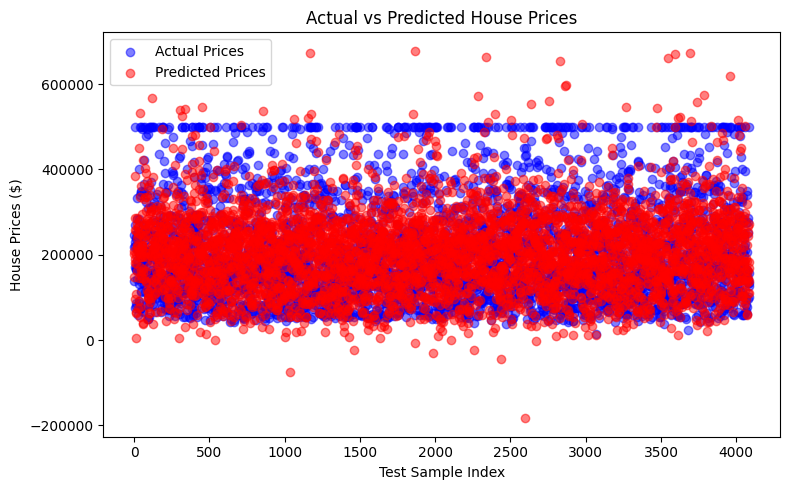

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    range(len(y_test)),
    y_test,
    color="blue",
    alpha=0.5,
    label="Actual Prices"
)

plt.scatter(
    range(len(linear_predictions)),
    linear_predictions,
    color="red",
    alpha=0.5,
    label="Predicted Prices"
)

plt.xlabel("Test Sample Index")
plt.ylabel("House Prices ($)")
plt.title("Actual vs Predicted House Prices")

plt.legend()
plt.tight_layout()
plt.show()

In [ ]:

sample_house = X_test.iloc[[0]]

predicted_price = linear_model.predict(sample_house)[0]

print(f"Predicted house price: ${predicted_price:,.2f}")
print(f"Actual house price: ${y_test.iloc[0]:,.2f}")

# Logistic Regression classification for the same house
predicted_class = logistic_model.predict(sample_house)[0]

if predicted_class == 1:
    print("Classification: Above the training median")
else:
    print("Classification: At or below the training median")


Predicted house price: $201,882.96
Actual house price: $245,800.00
Classification: At or below the training median


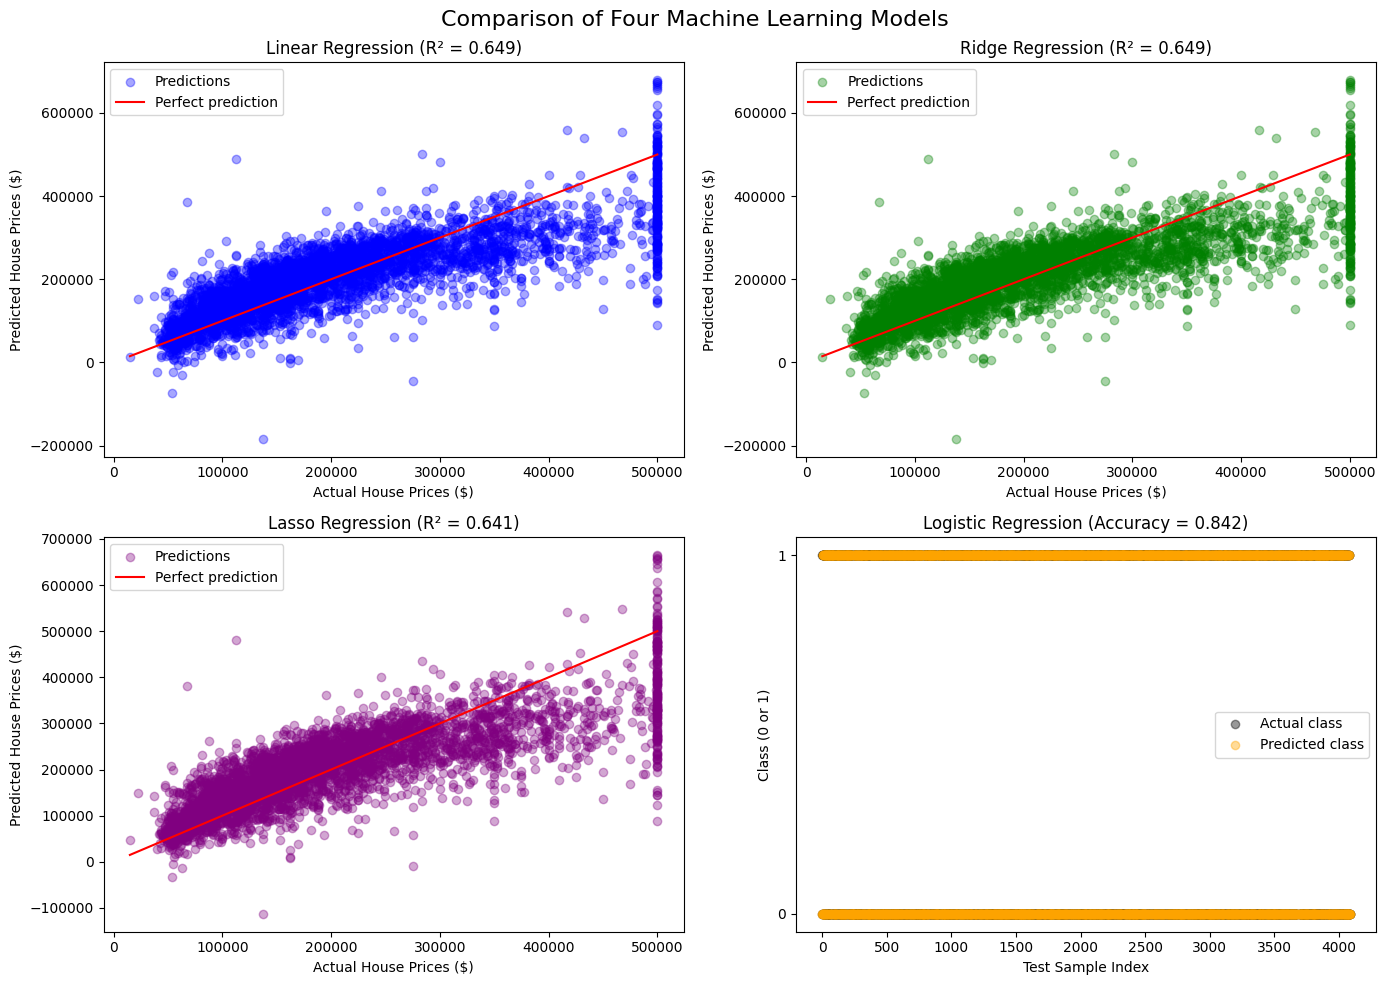

In [ ]:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score, accuracy_score

# Predictions from regression models
linear_predictions = linear_model.predict(X_test)
ridge_predictions = ridge_model.predict(X_test)
lasso_predictions = lasso_model.predict(X_test)

# Logistic Regression predicts classes, not prices
logistic_predictions = logistic_model.predict(X_test)

# Create a 2x2 visualization
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Linear Regression
axes[0, 0].scatter(
    y_test, linear_predictions,
    color="blue", alpha=0.35, label="Predictions"
)
axes[0, 0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red", label="Perfect prediction"
)
axes[0, 0].set_title(
    f"Linear Regression (R² = {r2_score(y_test, linear_predictions):.3f})"
)
axes[0, 0].set_xlabel("Actual House Prices ($)")
axes[0, 0].set_ylabel("Predicted House Prices ($)")
axes[0, 0].legend()

# 2. Ridge Regression
axes[0, 1].scatter(
    y_test, ridge_predictions,
    color="green", alpha=0.35, label="Predictions"
)
axes[0, 1].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red", label="Perfect prediction"
)
axes[0, 1].set_title(
    f"Ridge Regression (R² = {r2_score(y_test, ridge_predictions):.3f})"
)
axes[0, 1].set_xlabel("Actual House Prices ($)")
axes[0, 1].set_ylabel("Predicted House Prices ($)")
axes[0, 1].legend()

# 3. Lasso Regression
axes[1, 0].scatter(
    y_test, lasso_predictions,
    color="purple", alpha=0.35, label="Predictions"
)
axes[1, 0].plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red", label="Perfect prediction"
)
axes[1, 0].set_title(
    f"Lasso Regression (R² = {r2_score(y_test, lasso_predictions):.3f})"
)
axes[1, 0].set_xlabel("Actual House Prices ($)")
axes[1, 0].set_ylabel("Predicted House Prices ($)")
axes[1, 0].legend()

# 4. Logistic Regression classification
axes[1, 1].scatter(
    range(len(y_test_class)),
    y_test_class,
    color="black", alpha=0.4, label="Actual class"
)
axes[1, 1].scatter(
    range(len(logistic_predictions)),
    logistic_predictions,
    color="orange", alpha=0.4, label="Predicted class"
)
axes[1, 1].set_title(
    f"Logistic Regression (Accuracy = "
    f"{accuracy_score(y_test_class, logistic_predictions):.3f})"
)
axes[1, 1].set_xlabel("Test Sample Index")
axes[1, 1].set_ylabel("Class (0 or 1)")
axes[1, 1].set_yticks([0, 1])
axes[1, 1].legend()

plt.suptitle("Comparison of Four Machine Learning Models", fontsize=16)
plt.tight_layout()
plt.show()
